# PCE analysis: predictor comparison and feature selection

**Goal:** find the feature matrix that best predicts **headline PCE month-over-month % change** (`mom_headline`), the piece we need to chain onto the released months for the November 2026 YoY forecast. Every matrix is fit with OLS, so the comparison is about the predictors, not the model.

**Information timing.** Every matrix only uses what we will actually have in early December 2026:
- **Monthly releases (CPI, PPI, import prices, earnings):** lag 1. October is out by mid-November; November is not out until mid-December.
- **Market series (gasoline, oil, natural gas, dollar, equities):** lag 0. All of November is observed by early December.
- **`features_full.csv` (Haley's macro set):** used as built (lag 1 for market series, lag 2 for monthly releases).
- **PCE's own lags** are a course gray area, so they only appear in one clearly labeled matrix (M7).

**Plan:** (1) assemble predictor blocks → (2) define matrices M1–M4 → (3) forward/backward selection on 2007–2017 only → (4) expanding-window backtest 2018–2026 vs naive benchmarks. The main output is a **scoreboard of which FRED series earn a place**, not just which matrix wins.

Inputs come from `exploring_PCE.ipynb` (`data/fred_monthly_levels.csv`, `data/pce_group_targets.csv`) and `features_full.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"

SAMPLE_START = pd.Timestamp("2007-02-01")  # first month every group target and component proxy exists
SELECTION_END = pd.Timestamp("2017-12-01")  # feature selection only sees data up to here (~2 obs per parameter for M4)
BACKTEST_START = pd.Timestamp("2018-01-01")
SELECTION_ALPHA = 0.05  # F-test (= t-test for one column) threshold to enter in forward / stay in backward selection
COVID_START, COVID_END = pd.Timestamp("2020-03-01"), pd.Timestamp("2022-12-01")

# Market series observed daily/weekly, so November is fully known by early December -> lag 0 is legitimate.
MARKET_SERIES = ["retail_gasoline_weekly", "wti_oil", "henry_hub_gas", "usd_broad_index", "nasdaq_composite"]
# Proxies left out of the component block, with the reason (logged below).
EXCLUDED_PROXIES = {"sp500": "FRED history starts 2016-10 (licensing); nasdaq_composite covers equities"}

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 1.5, "legend.frameon": False,
})

## 1. Load data
All frames are indexed by calendar month (first day of month, `freq="MS"`). Monthly data has no time of day, so no timezone applies.

In [3]:
group_targets = pd.read_csv(DATA_DIR / "pce_group_targets.csv", index_col="month", parse_dates=True).asfreq("MS")
monthly_levels = pd.read_csv(DATA_DIR / "fred_monthly_levels.csv", index_col="month", parse_dates=True).asfreq("MS")
features_full = pd.read_csv(PROJECT_DIR / "features_full.csv", index_col="date", parse_dates=True).asfreq("MS")
features_full.index.name = "month"

target = group_targets["mom_headline"].rename("pce_mom")
for name, frame in [("group_targets", group_targets), ("monthly_levels", monthly_levels), ("features_full", features_full)]:
    print(f"{name}: {frame.shape}, {frame.index.min():%Y-%m} to {frame.index.max():%Y-%m}, freq={frame.index.freqstr}")
print(f"target pce_mom: {target.notna().sum()} months, {target.first_valid_index():%Y-%m} to {target.last_valid_index():%Y-%m}")

group_targets: (235, 17), 2007-02 to 2026-08, freq=MS
monthly_levels: (442, 48), 1990-01 to 2026-10, freq=MS
features_full: (335, 71), 1999-01 to 2026-11, freq=MS
target pce_mom: 235 months, 2007-02 to 2026-08


## 2. Build predictor blocks
- **Component proxies:** every `proxy` series from the `exploring_PCE.ipynb` catalog, as monthly % change. Monthly releases are lagged 1 month; market series are kept at lag 0 in a separate block so M2 vs M3 isolates their value.
- **Macro block (`features_full.csv`):** used as built, minus columns that don't belong (logged with reasons).

Note on `features_full.csv` transforms: price, activity and money columns are monthly % changes, but rates, breakevens, inflation expectations, unemployment and sentiment are **levels**, and jobless claims is a log level. Levels are slow-moving and partly trending, so they mostly act like a regime intercept for a monthly-change target. We keep them as built and let selection decide.

In [4]:
def pct_change_monthly(levels: pd.DataFrame) -> pd.DataFrame:
    """Month-over-month % change; the first row of each series is NaN by construction."""
    return 100 * (levels / levels.shift(1) - 1)


proxy_columns = [
    column for column in monthly_levels.columns
    if not column.startswith(("pce_", "nominal_", "real_")) and column not in EXCLUDED_PROXIES
]
for column, reason in EXCLUDED_PROXIES.items():
    print(f"Excluded proxy {column}: {reason}")

proxy_mom = pct_change_monthly(monthly_levels[proxy_columns])
release_columns = [column for column in proxy_columns if column not in MARKET_SERIES]
component_lag1 = proxy_mom[release_columns].shift(1).add_suffix("_L1")
market_lag0 = proxy_mom[MARKET_SERIES].add_suffix("_L0")
print(f"component_lag1: {component_lag1.shape[1]} columns (CPI/PPI/import prices/earnings, lag 1)")
print(f"market_lag0: {market_lag0.shape[1]} columns (market series, lag 0)")

Excluded proxy sp500: FRED history starts 2016-10 (licensing); nasdaq_composite covers equities
component_lag1: 29 columns (CPI/PPI/import prices/earnings, lag 1)
market_lag0: 5 columns (market series, lag 0)


In [5]:
OWN_PCE_COLUMNS = ["pce_L2", "pce_L3", "core_pce_L2", "core_pce_L3"]
MACRO_DROPS = {
    **{column: "own PCE lag (gray area, kept for M7 only)" for column in OWN_PCE_COLUMNS},
    "ppi_final_L2": "starts ~2010, would cut ~35 months from the 2007+ sample",
    "ppi_final_L3": "starts ~2010, would cut ~35 months from the 2007+ sample",
    "month": "calendar month as a 1-12 number has no linear meaning, and targets are seasonally adjusted",
    "covid_2020_2022": "added to every model separately as the shared COVID dummy",
}
target_columns = ["y_pce_mom", "y_pce_yoy"]
macro_all_lags = features_full.drop(columns=target_columns + list(MACRO_DROPS))
print(f"macro columns after drops: {macro_all_lags.shape[1]} of {features_full.shape[1]}")
for column, reason in MACRO_DROPS.items():
    print(f"  dropped {column}: {reason}")

# One lag per series: keep the most recent lag (L1 for market series, L2 for monthly releases).
# Adjacent lags of the same series are highly collinear and doubled the parameter count.
macro_series_name = pd.Series({column: column.rsplit("_L", 1)[0] for column in macro_all_lags.columns})
macro_lag_number = pd.Series({column: int(column.rsplit("_L", 1)[1]) for column in macro_all_lags.columns})
macro_keep = macro_lag_number.groupby(macro_series_name).idxmin().sort_values().tolist()
macro_block = macro_all_lags[macro_keep]
print(f"macro_block: kept {macro_block.shape[1]} columns (one lag per series), dropped {macro_all_lags.shape[1] - macro_block.shape[1]} older-lag duplicates")

# Shared COVID dummy, rebuilt from the dates and checked against features_full's version.
covid_dummy = pd.Series(((target.index >= COVID_START) & (target.index <= COVID_END)).astype(float), index=target.index, name="covid_2020_2022")
covid_mismatch = (covid_dummy - features_full["covid_2020_2022"].reindex(covid_dummy.index)).abs().sum()
print(f"COVID dummy: {int(covid_dummy.sum())} months flagged; mismatches vs features_full = {covid_mismatch:.0f}")

macro columns after drops: 61 of 71
  dropped pce_L2: own PCE lag (gray area, kept for M7 only)
  dropped pce_L3: own PCE lag (gray area, kept for M7 only)
  dropped core_pce_L2: own PCE lag (gray area, kept for M7 only)
  dropped core_pce_L3: own PCE lag (gray area, kept for M7 only)
  dropped ppi_final_L2: starts ~2010, would cut ~35 months from the 2007+ sample
  dropped ppi_final_L3: starts ~2010, would cut ~35 months from the 2007+ sample
  dropped month: calendar month as a 1-12 number has no linear meaning, and targets are seasonally adjusted
  dropped covid_2020_2022: added to every model separately as the shared COVID dummy
macro_block: kept 25 columns (one lag per series), dropped 36 older-lag duplicates
COVID dummy: 34 months flagged; mismatches vs features_full = 0


### 2.1 Cross-check `features_full.csv` against our FRED pull
Where both sources cover the same underlying series, they should agree after matching lags. A correlation near 1 with a small max gap means the CSV is built correctly; a gap points to a different series definition (e.g. end-of-month vs monthly-average prices) or a construction error.

In [6]:
HALEY_VS_FRED = [  # (features_full column, our FRED-derived series, lag already applied in features_full)
    ("cpi_L2", "cpi_headline", 2), ("core_cpi_L2", "cpi_core", 2), ("avg_hourly_earn_L2", "ahe_private", 2),
    ("usd_index_L1", "usd_broad_index", 1), ("oil_wti_L1", "wti_oil", 1), ("gasoline_L1", "retail_gasoline_weekly", 1),
    ("cpi_energy_L2", "cpi_gasoline", 2), ("cpi_food_L2", "cpi_food_at_home", 2), ("cpi_shelter_L2", "cpi_rent", 2),
    ("import_prices_L2", "import_px_consumer_goods", 2),
]
crosscheck_rows = []
for haley_column, fred_name, lag in HALEY_VS_FRED:
    pair = pd.concat([features_full[haley_column], proxy_mom[fred_name].shift(lag)], axis=1).loc[SAMPLE_START:].dropna()
    crosscheck_rows.append({
        "features_full_column": haley_column, "fred_series": fred_name, "n": len(pair),
        "corr": pair.iloc[:, 0].corr(pair.iloc[:, 1]), "max_abs_gap_pp": (pair.iloc[:, 0] - pair.iloc[:, 1]).abs().max(),
    })
pd.DataFrame(crosscheck_rows).round(4)

,features_full_column,fred_series,n,corr,max_abs_gap_pp
0,cpi_L2,cpi_headline,235,1.0000,0.0159
1,core_cpi_L2,cpi_core,235,1.0000,0.0033
2,avg_hourly_earn_L2,ahe_private,237,0.9999,0.1009
3,usd_index_L1,usd_broad_index,237,0.9999,0.2626
4,oil_wti_L1,wti_oil,237,0.9862,18.0227
5,gasoline_L1,retail_gasoline_weekly,237,0.9971,5.5126
6,cpi_energy_L2,cpi_gasoline,235,0.9827,11.2217
7,cpi_food_L2,cpi_food_at_home,235,0.9673,1.0505
8,cpi_shelter_L2,cpi_rent,235,0.8468,0.4983
9,import_prices_L2,import_px_consumer_goods,235,0.3605,7.2204


Reading the table: CPI, core CPI, hourly earnings and the dollar index match to ~1.000, so those columns are built correctly. Oil and gasoline correlate ~0.99 but have large single-month gaps, consistent with end-of-month vs monthly-average pricing. The energy, food and shelter rows compare *broader* CPI aggregates with our narrower components, so a lower correlation there is a definition difference, not an error. `import_prices` is all imports vs our consumer-goods import index: a different series.

## 3. Feature matrices
Every matrix gets an intercept and the COVID dummy. They all use the **same rows**: months where the target and every candidate column exist. That way differences in fit come from the predictors, not the sample.

**Known gap:** BLS never published October 2025 CPI (federal government shutdown), so CPI monthly changes for Oct and Nov 2025 can't be computed. At lag 1 and lag 2 that knocks out Nov 2025 – Jan 2026. Those months are dropped and logged below rather than imputed.

| ID | Matrix |
|---|---|
| M1 | Macro set from `features_full.csv` |
| M2 | Component proxies, lag 1 |
| M3 | M2 + market series at lag 0 |
| M4 | M1 ∪ M3 (kitchen sink) |
| M5 / M6 | Forward / backward selection from M4 (section 4) |
| M7 | M5 + PCE's own lags (**gray area**) |

In [7]:
candidate_pool = pd.concat([macro_block, component_lag1, market_lag0], axis=1)
model_frame = pd.concat([target, covid_dummy, candidate_pool], axis=1).loc[SAMPLE_START:target.last_valid_index()]

rows_before = len(model_frame)
incomplete_rows = model_frame.isna().any(axis=1)
missing_detail = model_frame.loc[incomplete_rows].isna().apply(lambda row: ", ".join(row.index[row]), axis=1)
model_frame = model_frame.loc[~incomplete_rows]
print(f"Common sample: kept {len(model_frame)} of {rows_before} months, {model_frame.index.min():%Y-%m} to {model_frame.index.max():%Y-%m}")
print(f"Dropped {incomplete_rows.sum()} months with missing predictors:")
for month, columns in missing_detail.items():
    print(f"  {month:%Y-%m}: {len(columns.split(', '))} missing ({columns[:110]}{'...' if len(columns) > 110 else ''})")
# Index has gaps after the drop, so it no longer carries an MS freq; rows stay in calendar order.
print(f"model_frame shape: {model_frame.shape}")

Common sample: kept 232 of 235 months, 2007-02 to 2026-08
Dropped 3 months with missing predictors:
  2025-11: 20 missing (cpi_electricity_L1, cpi_utility_gas_L1, cpi_food_at_home_L1, cpi_core_goods_L1, cpi_household_furnishings_L1, ...)
  2025-12: 27 missing (core_cpi_L2, cpi_L2, cpi_energy_L2, cpi_food_L2, cpi_shelter_L2, import_prices_L2, unemployment_L2, cpi_electr...)
  2026-01: 6 missing (core_cpi_L2, cpi_L2, cpi_energy_L2, cpi_food_L2, cpi_shelter_L2, import_prices_L2)
model_frame shape: (232, 61)


In [8]:
FEATURE_MATRICES = {
    "M1 macro (features_full)": list(macro_block.columns),
    "M2 component proxies L1": list(component_lag1.columns),
    "M3 components + market L0": list(component_lag1.columns) + list(market_lag0.columns),
    "M4 kitchen sink": list(macro_block.columns) + list(component_lag1.columns) + list(market_lag0.columns),
}
selection_rows = model_frame.loc[:SELECTION_END]
backtest_rows = model_frame.loc[BACKTEST_START:]
matrix_summary = pd.DataFrame({
    "n_predictors": {name: len(columns) for name, columns in FEATURE_MATRICES.items()},
    "params_incl_intercept_covid": {name: len(columns) + 2 for name, columns in FEATURE_MATRICES.items()},
})
matrix_summary["obs_per_param_full"] = (len(model_frame) / matrix_summary["params_incl_intercept_covid"]).round(1)
matrix_summary["obs_per_param_selection"] = (len(selection_rows) / matrix_summary["params_incl_intercept_covid"]).round(1)
print(f"Selection window: {len(selection_rows)} months ({selection_rows.index.min():%Y-%m} to {selection_rows.index.max():%Y-%m}); backtest window: {len(backtest_rows)} months")
matrix_summary

Selection window: 131 months (2007-02 to 2017-12); backtest window: 101 months


,n_predictors,params_incl_intercept_covid,obs_per_param_full,obs_per_param_selection
M1 macro (features_full),25,27,8.6,4.9
M2 component proxies L1,29,31,7.5,4.2
M3 components + market L0,34,36,6.4,3.6
M4 kitchen sink,59,61,3.8,2.1


## 4. Feature selection (2007–2017 only)
- **Forward:** start from the intercept; each step add the candidate with the smallest p-value, stop when none has p < 0.05.
- **Backward:** start from every candidate; each step remove the one with the largest p-value, stop when all have p < 0.05. Aliased (perfectly collinear) columns get a NaN p-value and are removed first.
- For a single added or removed column, the partial F-test and the t-test give the same p-value.
- R², adjusted R², AIC and BIC are tracked at every step, so we can see whether an information criterion would stop earlier than the p-value rule.
- **The COVID dummy is left out of these fits** because it is all zeros before 2018. It comes back in the backtest.

Both methods run on every base matrix. The M4 runs become **M5 (forward)** and **M6 (backward)**. The M1–M3 runs show the best subset from each source on its own.

In [9]:
TARGET = "pce_mom"


def fit_ols(frame: pd.DataFrame, predictors: list[str]) -> sm.regression.linear_model.RegressionResultsWrapper:
    """OLS of the target on an intercept plus the given predictor columns."""
    design = pd.DataFrame({"const": 1.0}, index=frame.index).join(frame[predictors])
    return sm.OLS(frame[TARGET], design).fit()


def step_record(model: sm.regression.linear_model.RegressionResultsWrapper, step: int, action: str, variable: str, p_value: float) -> dict:
    """One row of a selection path: what changed and the resulting fit statistics."""
    return {
        "step": step, "action": action, "variable": variable, "p_value": p_value, "n_predictors": int(model.df_model),
        "r2": model.rsquared, "adj_r2": model.rsquared_adj, "aic": model.aic, "bic": model.bic,
    }


def forward_selection(frame: pd.DataFrame, candidates: list[str], alpha: float) -> tuple[list[str], pd.DataFrame]:
    """Add the lowest-p-value candidate each step until no candidate has p < alpha."""
    selected, remaining = [], list(candidates)
    path = [step_record(fit_ols(frame, selected), 0, "start", "(intercept only)", np.nan)]
    while remaining:
        entry_pvalues = pd.Series({column: fit_ols(frame, selected + [column]).pvalues[column] for column in remaining})
        best = entry_pvalues.idxmin()
        if entry_pvalues[best] >= alpha:
            break
        selected.append(best)
        remaining.remove(best)
        path.append(step_record(fit_ols(frame, selected), len(path), "add", best, entry_pvalues[best]))
    return selected, pd.DataFrame(path)


def backward_selection(frame: pd.DataFrame, candidates: list[str], alpha: float) -> tuple[list[str], pd.DataFrame]:
    """Remove the highest-p-value predictor each step until all have p < alpha; aliased (NaN p) columns go first."""
    selected = list(candidates)
    model = fit_ols(frame, selected)
    path = [step_record(model, 0, "start", "(all candidates)", np.nan)]
    while selected:
        stay_pvalues = model.pvalues[selected]
        worst = stay_pvalues.fillna(np.inf).idxmax()
        if stay_pvalues.fillna(np.inf)[worst] < alpha:
            break
        selected.remove(worst)
        model = fit_ols(frame, selected)
        path.append(step_record(model, len(path), "remove", worst, stay_pvalues[worst]))
    return selected, pd.DataFrame(path)

In [10]:
# statsmodels solves OLS with a pseudo-inverse, so collinear columns don't crash it; check rank explicitly instead.
for name, columns in FEATURE_MATRICES.items():
    design = np.column_stack([np.ones(len(selection_rows)), selection_rows[columns].to_numpy()])
    rank = np.linalg.matrix_rank(design)
    print(f"{name}: {design.shape[1]} columns (incl. intercept), rank {rank} on {len(selection_rows)} selection rows -> {design.shape[1] - rank} aliased")

M1 macro (features_full): 26 columns (incl. intercept), rank 26 on 131 selection rows -> 0 aliased
M2 component proxies L1: 30 columns (incl. intercept), rank 30 on 131 selection rows -> 0 aliased
M3 components + market L0: 35 columns (incl. intercept), rank 35 on 131 selection rows -> 0 aliased
M4 kitchen sink: 60 columns (incl. intercept), rank 60 on 131 selection rows -> 0 aliased


In [11]:
selection_paths = {}
selected_sets = {}
for name, columns in FEATURE_MATRICES.items():
    for method, selector in [("forward", forward_selection), ("backward", backward_selection)]:
        chosen, path = selector(selection_rows, columns, SELECTION_ALPHA)
        selected_sets[(name, method)] = chosen
        selection_paths[(name, method)] = path

selection_summary = pd.DataFrame([
    {
        "matrix": name, "method": method, "n_candidates": len(FEATURE_MATRICES[name]), "n_selected": len(chosen),
        "adj_r2": selection_paths[(name, method)]["adj_r2"].iloc[-1], "bic": selection_paths[(name, method)]["bic"].iloc[-1],
        "selected": ", ".join(chosen),
    }
    for (name, method), chosen in selected_sets.items()
]).round(3)
pd.set_option("display.max_colwidth", 200)
selection_summary

,matrix,method,n_candidates,n_selected,adj_r2,bic,selected
0,M1 macro (features_full),forward,25,4,0.492,-93.567,"usd_index_L1, oil_wti_L1, import_prices_L2, cpi_energy_L2"
1,M1 macro (features_full),backward,25,6,0.505,-89.277,"breakeven_10y_L1, breakeven_5y_L1, ind_production_L2, m2_L2, oil_wti_L1, usd_index_L1"
2,M2 component proxies L1,forward,29,4,0.379,-67.367,"cpi_headline_L1, cpi_airline_fares_L1, cpi_food_away_L1, cpi_gasoline_L1"
3,M2 component proxies L1,backward,29,4,0.379,-67.367,"cpi_gasoline_L1, cpi_food_away_L1, cpi_airline_fares_L1, cpi_headline_L1"
4,M3 components + market L0,forward,34,4,0.764,-194.120,"retail_gasoline_weekly_L0, cpi_headline_L1, usd_broad_index_L0, cpi_airline_fares_L1"
5,M3 components + market L0,backward,34,7,0.777,-189.780,"cpi_core_goods_L1, cpi_used_cars_L1, cpi_apparel_L1, cpi_airline_fares_L1, cpi_headline_L1, retail_gasoline_weekly_L0, usd_broad_index_L0"
6,M4 kitchen sink,forward,59,9,0.819,-209.677,"retail_gasoline_weekly_L0, import_prices_L2, cpi_airline_fares_L1, ind_production_L2, cpi_energy_L2, cpi_services_less_energy_L1, avg_hourly_earn_L2, wti_oil_L0, cpi_personal_care_L1"
7,M4 kitchen sink,backward,59,20,0.856,-198.362,"avg_hourly_earn_L2, core_cpi_L2, cpi_energy_L2, cpi_shelter_L2, gasoline_L1, import_prices_L2, ind_production_L2, jobless_claims_L1, payrolls_L2, sentiment_L1, cpi_utility_gas_L1, cpi_new_vehicles..."


### 4.1 Selection paths for the kitchen sink (M4)
Each row is one step. Watch where BIC bottoms out: if it bottoms out well before the p-value rule stops, the extra variables are buying very little fit for their parameters.

In [12]:
m4_forward_path = selection_paths[("M4 kitchen sink", "forward")]
m4_backward_path = selection_paths[("M4 kitchen sink", "backward")]
print(f"Forward: stopped at step {m4_forward_path['step'].iloc[-1]}; BIC minimum at step {m4_forward_path.loc[m4_forward_path['bic'].idxmin(), 'step']}")
print(f"Backward: stopped after {len(m4_backward_path) - 1} removals; BIC minimum at {m4_backward_path.loc[m4_backward_path['bic'].idxmin(), 'n_predictors']} predictors")
m4_forward_path.round(4)

Forward: stopped at step 9; BIC minimum at step 9
Backward: stopped after 39 removals; BIC minimum at 20 predictors


,step,action,variable,p_value,n_predictors,r2,adj_r2,aic,bic
0,0,start,(intercept only),NaN,0,0.0000,0.0000,-23.1536,-20.2784
1,1,add,retail_gasoline_weekly_L0,0.0000,1,0.6683,0.6657,-165.7068,-159.9564
2,2,add,import_prices_L2,0.0000,2,0.7438,0.7398,-197.5373,-188.9117
3,3,add,cpi_airline_fares_L1,0.0004,3,0.7682,0.7627,-208.6598,-197.1590
4,4,add,ind_production_L2,0.0009,4,0.7877,0.7809,-218.1621,-203.7862
5,5,add,cpi_energy_L2,0.0106,5,0.7985,0.7905,-223.0340,-205.7828
6,6,add,cpi_services_less_energy_L1,0.0217,6,0.8069,0.7976,-226.6228,-206.4965
7,7,add,avg_hourly_earn_L2,0.0091,7,0.8174,0.8070,-231.8907,-208.8892
8,8,add,wti_oil_L0,0.0234,8,0.8249,0.8135,-235.4337,-209.5569
9,9,add,cpi_personal_care_L1,0.0321,9,0.8315,0.8190,-238.4289,-209.6769


In [13]:
m4_backward_path.tail(12).round(4)

,step,action,variable,p_value,n_predictors,r2,adj_r2,aic,bic
28,28,remove,mortgage_30y_L1,0.3218,31,0.9018,0.8710,-265.1549,-173.1486
29,29,remove,cpi_vehicle_repair_L1,0.2075,30,0.9002,0.8702,-265.0422,-175.9111
30,30,remove,breakeven_5y_L1,0.1508,29,0.8981,0.8688,-264.3241,-178.0682
31,31,remove,breakeven_10y_L1,0.5540,28,0.8977,0.8697,-265.8676,-182.4869
32,32,remove,cpi_tuition_childcare_L1,0.1271,27,0.8954,0.8679,-264.8638,-184.3582
33,33,remove,cpi_food_at_home_L1,0.1770,26,0.8935,0.8669,-264.5339,-186.9036
34,34,remove,ppi_physicians_L1,0.2357,25,0.8920,0.8663,-264.7545,-189.9993
35,35,remove,umich_infl_exp_L1,0.1296,24,0.8896,0.8646,-263.8743,-191.9944
36,36,remove,job_openings_L2,0.1316,23,0.8872,0.8630,-263.0518,-194.0470
37,37,remove,import_px_consumer_goods_L1,0.1099,22,0.8845,0.8610,-261.9081,-195.7785


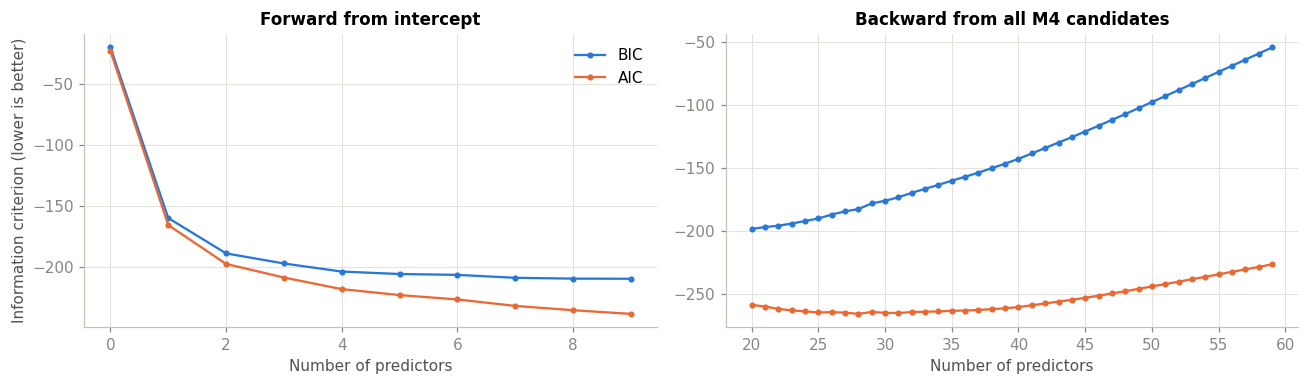

In [14]:
fig, (ax_forward, ax_backward) = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, path, title in [(ax_forward, m4_forward_path, "Forward from intercept"), (ax_backward, m4_backward_path, "Backward from all M4 candidates")]:
    ax.plot(path["n_predictors"], path["bic"], marker="o", markersize=3, color="#2a78d6", label="BIC")
    ax.plot(path["n_predictors"], path["aic"], marker="o", markersize=3, color="#eb6834", label="AIC")
    ax.set_xlabel("Number of predictors")
    ax.set_title(title)
ax_forward.set_ylabel("Information criterion (lower is better)")
ax_forward.legend()
plt.tight_layout()
plt.show()

### 4.2 Collinearity in the selected sets
VIF above ~5 means a predictor is largely explained by the others in the set, so its coefficient is unstable even if the forecast is fine.

In [15]:
def vif_table(frame: pd.DataFrame, predictors: list[str]) -> pd.Series:
    """Variance inflation factor for each predictor (intercept included in the design, not reported)."""
    design = pd.DataFrame({"const": 1.0}, index=frame.index).join(frame[predictors]).to_numpy()
    return pd.Series([variance_inflation_factor(design, position + 1) for position in range(len(predictors))], index=predictors, name="vif")


for method in ["forward", "backward"]:
    chosen = selected_sets[("M4 kitchen sink", method)]
    print(f"\nM4 {method} ({len(chosen)} predictors), VIF on the selection window:")
    print(vif_table(selection_rows, chosen).sort_values(ascending=False).round(2).to_string())


M4 forward (9 predictors), VIF on the selection window:
import_prices_L2               3.98
cpi_energy_L2                  3.75
retail_gasoline_weekly_L0      2.35
wti_oil_L0                     2.08
cpi_airline_fares_L1           1.33
cpi_services_less_energy_L1    1.23
ind_production_L2              1.13
cpi_personal_care_L1           1.12
avg_hourly_earn_L2             1.07

M4 backward (20 predictors), VIF on the selection window:
cpi_core_L1                    14.76
cpi_services_less_energy_L1    13.79
jobless_claims_L1               9.62
cpi_headline_L1                 6.77
sentiment_L1                    5.81
import_prices_L2                5.55
gasoline_L1                     5.29
cpi_shelter_L2                  4.45
cpi_energy_L2                   4.07
payrolls_L2                     3.40
core_cpi_L2                     2.67
cpi_used_cars_L1                2.51
cpi_new_vehicles_L1             2.47
cpi_apparel_L1                  2.36
retail_gasoline_weekly_L0       2.04
cpi_u

### 4.3 Predictor scoreboard
Every candidate column, where it came from, its univariate correlation with PCE MoM in the selection window, and how many of the 8 selection runs kept it. This is the main answer to *which FRED series are worth carrying forward*.

In [16]:
column_source = {
    **{column: "features_full macro" for column in macro_block.columns},
    **{column: "FRED component (L1)" for column in component_lag1.columns},
    **{column: "FRED market (L0)" for column in market_lag0.columns},
}
scoreboard = pd.DataFrame({
    "source": pd.Series(column_source),
    "corr_with_target": selection_rows[list(column_source)].corrwith(selection_rows[TARGET]),
    "times_selected": pd.Series({column: sum(column in chosen for chosen in selected_sets.values()) for column in column_source}),
    "in_M4_forward": pd.Series({column: column in selected_sets[("M4 kitchen sink", "forward")] for column in column_source}),
    "in_M4_backward": pd.Series({column: column in selected_sets[("M4 kitchen sink", "backward")] for column in column_source}),
})
scoreboard["abs_corr"] = scoreboard["corr_with_target"].abs()
scoreboard = scoreboard.sort_values(["times_selected", "abs_corr"], ascending=False).drop(columns="abs_corr")
print(f"{(scoreboard['times_selected'] > 0).sum()} of {len(scoreboard)} candidates selected at least once")
scoreboard[scoreboard["times_selected"] > 0].round(3)

30 of 59 candidates selected at least once


,source,corr_with_target,times_selected,in_M4_forward,in_M4_backward
cpi_airline_fares_L1,FRED component (L1),0.456,6,True,True
cpi_headline_L1,FRED component (L1),0.527,5,False,True
retail_gasoline_weekly_L0,FRED market (L0),0.817,4,True,True
usd_broad_index_L0,FRED market (L0),-0.499,3,False,True
import_prices_L2,features_full macro,0.455,3,True,True
ind_production_L2,features_full macro,0.286,3,True,True
cpi_energy_L2,features_full macro,0.202,3,True,True
usd_index_L1,features_full macro,-0.591,2,False,False
oil_wti_L1,features_full macro,0.587,2,False,False
cpi_gasoline_L1,FRED component (L1),0.426,2,False,False


In [17]:
FEATURE_MATRICES["M5 forward from M4"] = selected_sets[("M4 kitchen sink", "forward")]
FEATURE_MATRICES["M6 backward from M4"] = selected_sets[("M4 kitchen sink", "backward")]
for name in ["M5 forward from M4", "M6 backward from M4"]:
    print(f"{name}: {len(FEATURE_MATRICES[name])} predictors")
shared = sorted(set(FEATURE_MATRICES["M5 forward from M4"]) & set(FEATURE_MATRICES["M6 backward from M4"]))
print(f"Chosen by both: {len(shared)} -> {', '.join(shared)}")

M5 forward from M4: 9 predictors
M6 backward from M4: 20 predictors
Chosen by both: 7 -> avg_hourly_earn_L2, cpi_airline_fares_L1, cpi_energy_L2, cpi_services_less_energy_L1, import_prices_L2, ind_production_L2, retail_gasoline_weekly_L0


## 5. Expanding-window backtest, 2018–2026
For every month *t* from 2018-01: fit on all months before *t*, predict *t*. The selected sets (M5, M6, per-source forward sets) stay frozen from section 4, so the backtest never sees data that chose them.

- **COVID dummy:** included in the training fit once the window contains COVID months, but **set to 0 when predicting**. In real time nobody knew a month was a "COVID month", so the backtest shouldn't either.
- **Benchmarks:** B0 the expanding historical mean (intercept-only OLS), B1 last month's PCE change, B2 the average of the last 3 months.
- **M7 (gray area):** M5 plus last month's headline PCE change. October PCE is out by late November, so lag 1 is available for the real forecast; whether it's *allowed* is the instructor's call.
- **Scores:** MAE and RMSE in percentage points over all backtest months, MAE excluding the COVID window, and MAE on Novembers only (tiny n, indicative).

In [18]:
headline_mom_full = pct_change_monthly(monthly_levels[["pce_headline"]])["pce_headline"]  # from 1990, so lags exist at 2007-02
model_frame["pce_mom_L1"] = headline_mom_full.shift(1).reindex(model_frame.index)
benchmark_forecasts = pd.DataFrame({
    "B1 last month": headline_mom_full.shift(1),
    "B2 3-month average": headline_mom_full.shift(1).rolling(3).mean(),
}).reindex(model_frame.index)
gap_check = (headline_mom_full.reindex(model_frame.index) - model_frame[TARGET]).abs().max()
print(f"pce_mom_L1 and benchmarks built from monthly_levels; max |diff| vs target = {gap_check:.2e} (same series, so ~0)")

BACKTEST_MODELS = {
    "B0 expanding mean": [],
    **FEATURE_MATRICES,
    "M1 forward only": selected_sets[("M1 macro (features_full)", "forward")],
    "M2 forward only": selected_sets[("M2 component proxies L1", "forward")],
    "M3 forward only": selected_sets[("M3 components + market L0", "forward")],
    "M7 M5 + own PCE lag (gray area)": FEATURE_MATRICES["M5 forward from M4"] + ["pce_mom_L1"],
}
print(f"{len(BACKTEST_MODELS)} regression models + {benchmark_forecasts.shape[1]} naive benchmarks")

pce_mom_L1 and benchmarks built from monthly_levels; max |diff| vs target = 1.11e-16 (same series, so ~0)
11 regression models + 2 naive benchmarks


In [19]:
COVID_COLUMN = "covid_2020_2022"


def expanding_window_forecasts(frame: pd.DataFrame, predictors: list[str], start: pd.Timestamp) -> pd.Series:
    """Fit on every month before t and predict t, for each month from start; COVID dummy is fit but set to 0 when predicting."""
    predictions = {}
    for month in frame.index[frame.index >= start]:
        train = frame.loc[frame.index < month]
        columns = list(predictors) + ([COVID_COLUMN] if train[COVID_COLUMN].any() else [])
        model = fit_ols(train, columns)
        forecast_row = pd.DataFrame({"const": 1.0}, index=[month]).join(frame.loc[[month], columns])
        if COVID_COLUMN in columns:
            forecast_row[COVID_COLUMN] = 0.0
        predictions[month] = model.predict(forecast_row).iloc[0]
    return pd.Series(predictions)


backtest_forecasts = pd.DataFrame({name: expanding_window_forecasts(model_frame, predictors, BACKTEST_START) for name, predictors in BACKTEST_MODELS.items()})
backtest_forecasts = backtest_forecasts.join(benchmark_forecasts.loc[backtest_forecasts.index])
backtest_actual = model_frame.loc[backtest_forecasts.index, TARGET]
print(f"backtest_forecasts shape: {backtest_forecasts.shape}, {backtest_forecasts.index.min():%Y-%m} to {backtest_forecasts.index.max():%Y-%m}")
print(f"Missing forecasts: {int(backtest_forecasts.isna().sum().sum())}")

backtest_forecasts shape: (101, 13), 2018-01 to 2026-08
Missing forecasts: 0


In [20]:
def forecast_scores(actual: pd.Series, predicted: pd.Series) -> dict:
    """MAE and RMSE (pp) over all months, MAE outside the COVID window, and MAE on Novembers."""
    errors = predicted - actual
    outside_covid = (errors.index < COVID_START) | (errors.index > COVID_END)
    november = errors.index.month == 11
    return {
        "mae": errors.abs().mean(), "rmse": np.sqrt((errors ** 2).mean()),
        "mae_ex_covid": errors[outside_covid].abs().mean(), "mae_november": errors[november].abs().mean(),
        "n": len(errors), "n_ex_covid": int(outside_covid.sum()), "n_november": int(november.sum()),
    }


in_sample_fits = {
    name: fit_ols(model_frame, predictors + [COVID_COLUMN]) for name, predictors in BACKTEST_MODELS.items()
}
comparison = pd.DataFrame({name: forecast_scores(backtest_actual, backtest_forecasts[name]) for name in backtest_forecasts.columns}).T
comparison["n_predictors"] = pd.Series({name: len(predictors) for name, predictors in BACKTEST_MODELS.items()})
comparison["in_sample_adj_r2"] = pd.Series({name: fit.rsquared_adj for name, fit in in_sample_fits.items()})
comparison["in_sample_bic"] = pd.Series({name: fit.bic for name, fit in in_sample_fits.items()})
best_benchmark_mae = comparison.loc[comparison.index.str.startswith("B"), "mae"].min()
comparison["mae_vs_best_benchmark"] = comparison["mae"] / best_benchmark_mae
comparison = comparison.sort_values("mae")
print(f"Best benchmark MAE: {best_benchmark_mae:.3f} pp. In-sample columns are full-sample 2007-2026 fits with the COVID dummy.")
comparison[["n_predictors", "mae", "rmse", "mae_ex_covid", "mae_november", "mae_vs_best_benchmark", "in_sample_adj_r2", "in_sample_bic", "n", "n_ex_covid", "n_november"]].round(3)

Best benchmark MAE: 0.139 pp. In-sample columns are full-sample 2007-2026 fits with the COVID dummy.


,n_predictors,mae,rmse,mae_ex_covid,mae_november,mae_vs_best_benchmark,in_sample_adj_r2,in_sample_bic,n,n_ex_covid,n_november
M3 components + market L0,34.0,0.105,0.145,0.063,0.083,0.759,0.786,-234.551,101.0,67.0,7.0
M3 forward only,4.0,0.119,0.162,0.077,0.108,0.855,0.733,-313.992,101.0,67.0,7.0
M4 kitchen sink,59.0,0.121,0.192,0.091,0.067,0.871,0.813,-161.202,101.0,67.0,7.0
M7 M5 + own PCE lag (gray area),10.0,0.122,0.178,0.078,0.102,0.880,0.761,-313.260,101.0,67.0,7.0
M5 forward from M4,9.0,0.124,0.183,0.077,0.115,0.890,0.757,-313.558,101.0,67.0,7.0
M6 backward from M4,20.0,0.125,0.186,0.068,0.081,0.899,0.811,-324.406,101.0,67.0,7.0
B1 last month,NaN,0.139,0.198,0.114,0.095,1.000,NaN,NaN,101.0,67.0,7.0
B2 3-month average,NaN,0.139,0.187,0.106,0.108,1.001,NaN,NaN,101.0,67.0,7.0
M2 forward only,4.0,0.152,0.204,0.096,0.136,1.091,0.393,-123.353,101.0,67.0,7.0
M1 macro (features_full),25.0,0.156,0.269,0.106,0.123,1.119,0.521,-86.459,101.0,67.0,7.0


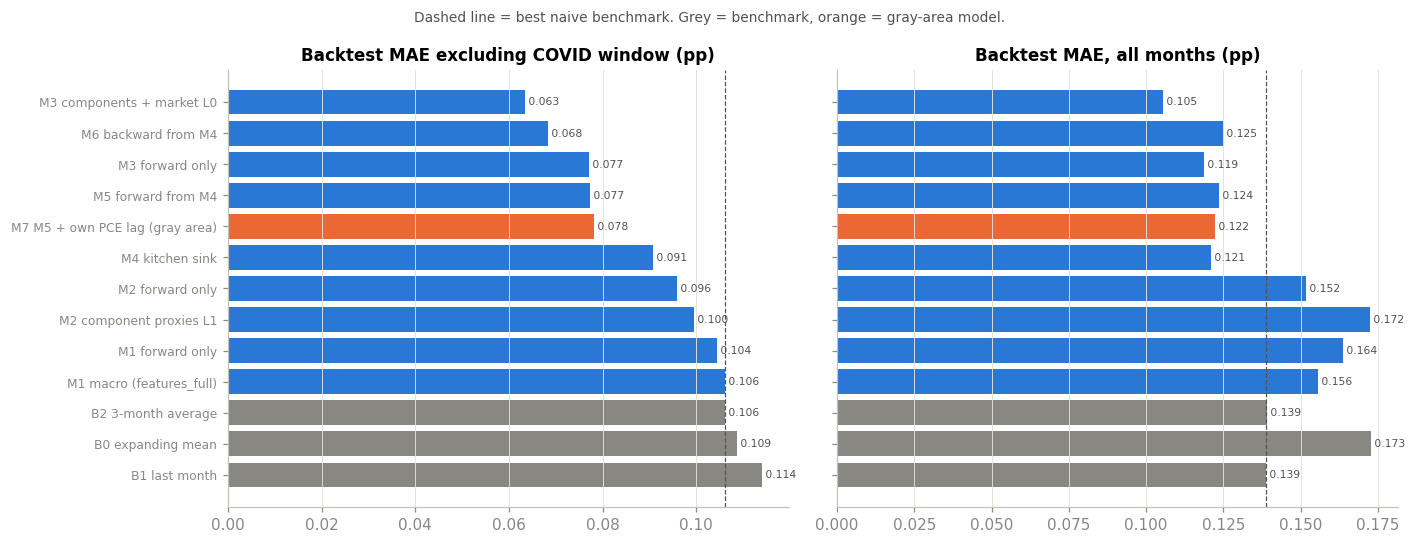

In [21]:
def bar_color(name: str) -> str:
    """Grey for naive benchmarks, orange for the gray-area model, blue for the rest."""
    if name.startswith("B"):
        return "#898781"
    if "gray area" in name:
        return "#eb6834"
    return "#2a78d6"


fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
order = comparison.sort_values("mae_ex_covid", ascending=False).index
for ax, column, title in [(axes[0], "mae_ex_covid", "Backtest MAE excluding COVID window (pp)"), (axes[1], "mae", "Backtest MAE, all months (pp)")]:
    ax.barh(order, comparison.loc[order, column], color=[bar_color(name) for name in order])
    ax.axvline(comparison.loc[comparison.index.str.startswith("B"), column].min(), color="#52514e", linewidth=0.8, linestyle="--")
    for position, value in enumerate(comparison.loc[order, column]):
        ax.text(value, position, f" {value:.3f}", va="center", fontsize=7, color="#52514e")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].tick_params(axis="y", labelsize=8)
fig.suptitle("Dashed line = best naive benchmark. Grey = benchmark, orange = gray-area model.", fontsize=9, color="#52514e")
plt.tight_layout()
plt.show()

Best non-benchmark, non-gray-area model by MAE ex-COVID: M3 components + market L0


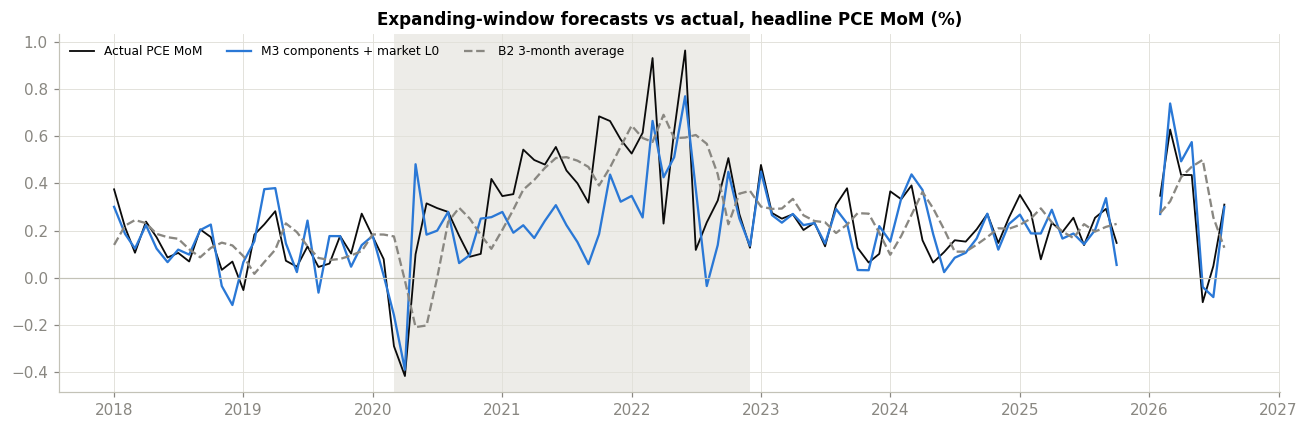

In [22]:
best_model = comparison.drop(index=[name for name in comparison.index if name.startswith("B") or "gray area" in name])["mae_ex_covid"].idxmin()
print(f"Best non-benchmark, non-gray-area model by MAE ex-COVID: {best_model}")
# Reindex to every month so the dropped shutdown months show as gaps instead of a straight line.
plot_actual = backtest_actual.asfreq("MS")
plot_forecasts = backtest_forecasts.asfreq("MS")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(plot_actual.index, plot_actual, color="#0b0b0b", linewidth=1.2, label="Actual PCE MoM")
ax.plot(plot_forecasts.index, plot_forecasts[best_model], color="#2a78d6", label=best_model)
ax.plot(plot_forecasts.index, plot_forecasts["B2 3-month average"], color="#898781", linestyle="--", label="B2 3-month average")
ax.axvspan(COVID_START, COVID_END, color="#e1e0d9", alpha=0.6, linewidth=0, zorder=0)
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
ax.set_title("Expanding-window forecasts vs actual, headline PCE MoM (%)")
ax.legend(fontsize=8, ncol=3, loc="upper left")
plt.tight_layout()
plt.show()

### 5.1 Coefficients of the best model (full sample, 2007–2026)
Fit on every month with the COVID dummy. Coefficients are in pp of PCE MoM per 1 pp of the predictor's monthly change (or per unit of level for level columns).

In [23]:
best_fit = in_sample_fits[best_model]
print(f"{best_model}: n = {int(best_fit.nobs)}, adj R² = {best_fit.rsquared_adj:.3f}, BIC = {best_fit.bic:.1f}")
best_fit.summary2().tables[1].round(4)

M3 components + market L0: n = 232, adj R² = 0.786, BIC = -234.6


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,0.0198,0.0268,0.7391,0.4607,-0.0330,0.0726
cpi_gasoline_L1,-0.0091,0.0058,-1.5733,0.1173,-0.0205,0.0023
cpi_electricity_L1,-0.0036,0.0127,-0.2833,0.7772,-0.0286,0.0214
cpi_utility_gas_L1,0.0022,0.0038,0.5689,0.5701,-0.0053,0.0096
cpi_food_at_home_L1,0.0447,0.0303,1.4751,0.1418,-0.0150,0.1043
ppi_consumer_foods_L1,-0.0021,0.0076,-0.2808,0.7791,-0.0172,0.0129
cpi_core_goods_L1,-0.5499,0.2304,-2.3870,0.0179,-1.0042,-0.0956
cpi_new_vehicles_L1,0.0806,0.0275,2.9254,0.0038,0.0262,0.1349
cpi_used_cars_L1,0.0277,0.0124,2.2363,0.0265,0.0033,0.0521
cpi_household_furnishings_L1,0.0536,0.0333,1.6110,0.1088,-0.0120,0.1192


In [24]:
# 5.2 Best model refit with only the predictors that are significant at p < SELECTION_ALPHA (one pass: drop all non-significant at once).
def significant_predictors(model: sm.regression.linear_model.RegressionResultsWrapper, candidates: list[str], alpha: float) -> list[str]:
    """Candidates whose coefficient p-value in the fitted model is below alpha."""
    return [column for column in candidates if model.pvalues[column] < alpha]


best_predictors = BACKTEST_MODELS[best_model]
# A: p-values from the full-sample fit in 5.1. That fit saw the 2018-2026 backtest months, so A's backtest is optimistic.
full_sample_kept = significant_predictors(in_sample_fits[best_model], best_predictors, SELECTION_ALPHA)
# B: p-values from a fit on 2007-2017 only (no COVID dummy, as in section 4), so B's backtest stays out of sample.
selection_window_kept = significant_predictors(fit_ols(selection_rows, best_predictors), best_predictors, SELECTION_ALPHA)

significant_only_models = {
    "A: significant in full-sample fit": full_sample_kept,
    "B: significant in 2007-2017 fit": selection_window_kept,
}
for name, kept in significant_only_models.items():
    dropped = [column for column in best_predictors if column not in kept]
    print(f"{name}: kept {len(kept)} of {len(best_predictors)} predictors, dropped {len(dropped)}")
    print(f"  kept: {', '.join(kept)}")

significant_only_forecasts = pd.DataFrame({name: expanding_window_forecasts(model_frame, kept, BACKTEST_START) for name, kept in significant_only_models.items()})
significant_only_fits = {name: fit_ols(model_frame, kept + [COVID_COLUMN]) for name, kept in significant_only_models.items()}
significant_only_scores = pd.DataFrame({name: forecast_scores(backtest_actual, significant_only_forecasts[name]) for name in significant_only_forecasts.columns}).T
significant_only_scores["n_predictors"] = [len(kept) for kept in significant_only_models.values()]
significant_only_scores["in_sample_adj_r2"] = [fit.rsquared_adj for fit in significant_only_fits.values()]
significant_only_scores["in_sample_bic"] = [fit.bic for fit in significant_only_fits.values()]
significant_only_scores["mae_vs_best_benchmark"] = significant_only_scores["mae"] / best_benchmark_mae

score_columns = ["n_predictors", "mae", "rmse", "mae_ex_covid", "mae_november", "mae_vs_best_benchmark", "in_sample_adj_r2", "in_sample_bic"]
reference_rows = [best_model, "M3 forward only", "B1 last month", "B2 3-month average"]
display(pd.concat([comparison.loc[reference_rows, score_columns], significant_only_scores[score_columns]]).round(3))

for name, fit in significant_only_fits.items():
    print(f"\n{name}, refit on the full sample with the COVID dummy (p-values shift once the other columns are gone):")
    display(fit.summary2().tables[1].round(4))


A: significant in full-sample fit: kept 8 of 34 predictors, dropped 26
  kept: cpi_core_goods_L1, cpi_new_vehicles_L1, cpi_used_cars_L1, cpi_oer_L1, cpi_airline_fares_L1, cpi_headline_L1, retail_gasoline_weekly_L0, usd_broad_index_L0
B: significant in 2007-2017 fit: kept 6 of 34 predictors, dropped 28
  kept: cpi_used_cars_L1, cpi_apparel_L1, cpi_airline_fares_L1, cpi_headline_L1, retail_gasoline_weekly_L0, usd_broad_index_L0


,n_predictors,mae,rmse,mae_ex_covid,mae_november,mae_vs_best_benchmark,in_sample_adj_r2,in_sample_bic
M3 components + market L0,34.0,0.105,0.145,0.063,0.083,0.759,0.786,-234.551
M3 forward only,4.0,0.119,0.162,0.077,0.108,0.855,0.733,-313.992
B1 last month,NaN,0.139,0.198,0.114,0.095,1.000,NaN,NaN
B2 3-month average,NaN,0.139,0.187,0.106,0.108,1.001,NaN,NaN
A: significant in full-sample fit,8.0,0.103,0.137,0.063,0.089,0.738,0.771,-332.379
B: significant in 2007-2017 fit,6.0,0.120,0.163,0.077,0.106,0.862,0.731,-303.151



A: significant in full-sample fit, refit on the full sample with the COVID dummy (p-values shift once the other columns are gone):


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,0.0485,0.0145,3.3327,0.0010,0.0198,0.0771
cpi_core_goods_L1,-0.0583,0.0472,-1.2354,0.2180,-0.1512,0.0347
cpi_new_vehicles_L1,0.0758,0.0237,3.1923,0.0016,0.0290,0.1226
cpi_used_cars_L1,0.0126,0.0081,1.5495,0.1227,-0.0034,0.0286
cpi_oer_L1,0.2960,0.0526,5.6246,0.0000,0.1923,0.3996
cpi_airline_fares_L1,0.0076,0.0026,2.8992,0.0041,0.0024,0.0128
cpi_headline_L1,0.1339,0.0296,4.5307,0.0000,0.0757,0.1921
retail_gasoline_weekly_L0,0.0212,0.0012,16.9993,0.0000,0.0187,0.0236
usd_broad_index_L0,-0.0234,0.0056,-4.1950,0.0000,-0.0344,-0.0124
covid_2020_2022,0.1037,0.0238,4.3604,0.0000,0.0568,0.1505



B: significant in 2007-2017 fit, refit on the full sample with the COVID dummy (p-values shift once the other columns are gone):


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,0.1127,0.0097,11.5919,0.0000,0.0936,0.1319
cpi_used_cars_L1,0.0009,0.0054,0.1588,0.8740,-0.0097,0.0114
cpi_apparel_L1,-0.0025,0.0148,-0.1681,0.8667,-0.0316,0.0266
cpi_airline_fares_L1,0.0066,0.0029,2.2970,0.0225,0.0009,0.0122
cpi_headline_L1,0.1879,0.0312,6.0305,0.0000,0.1265,0.2493
retail_gasoline_weekly_L0,0.0204,0.0013,15.1480,0.0000,0.0177,0.0230
usd_broad_index_L0,-0.0245,0.0060,-4.0751,0.0001,-0.0363,-0.0126
covid_2020_2022,0.1518,0.0233,6.5147,0.0000,0.1059,0.1977


In [ ]:
# 5.3 Same in-sample regression as 5.1 (all 232 months, intercept + COVID dummy), keeping only the predictors significant in 5.1 (version A above).
significant_fit = significant_only_fits["A: significant in full-sample fit"]
print(f"{best_model}, significant predictors only: n = {int(significant_fit.nobs)}, adj R² = {significant_fit.rsquared_adj:.3f}, BIC = {significant_fit.bic:.1f}")
adj_r2_comparison = pd.DataFrame({
    "n": [int(best_fit.nobs), int(significant_fit.nobs)],
    "n_predictors": [len(best_predictors), len(full_sample_kept)],
    "adj_r2": [best_fit.rsquared_adj, significant_fit.rsquared_adj],
    "bic": [best_fit.bic, significant_fit.bic],
}, index=["all predictors", f"p < {SELECTION_ALPHA} only"])
adj_r2_comparison.round(3)
